# Cancellation forecasting and smart overbooking
### Client report (public *Hotel Booking Demand* data + synthetic elements)

This notebook runs **the whole project** and shows the results intended for the client: diagnosis of the problem,
model quality, the overbooking backtest, the plan for the coming weeks, the list of bookings to contact,
cancellation-policy analysis, monitoring and the business case.

> Items marked **SYNTHETIC** (walk cost, turned-away demand on sold-out nights,
> effect of guest contact, effect of prepayment) are assumptions - all of them live in `config.py`.

Run time: approx. 1-2 minutes.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

%matplotlib inline
import pandas as pd
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

import config as C
from src.pipeline import run_all
from src.report import show, write_html, write_excel

R = run_all(as_of=C.DEMO_AS_OF)      # full pipeline: data -> models -> backtest -> plan -> report
T, F = R["tables"], R["figures"]

[   0.0s] 1/9 Loading and cleaning data


[   1.2s] 2/9 Leakage-free snapshots + model training


  snapshots: train=204,602  valid=134,831  test=175,763


  training logistic regression ...


  training LightGBM ...


...

[  59.0s] 5/9 Backtest of overbooking policies (2017)


[  60.8s] 6/9 A/B experiment on preventive actions [synthetic]
[  61.0s] 7/9 Segment and policy analysis


[  61.1s] 8/9 Overbooking plan and risk list as of 2017-06-15


[  62.5s] 9/9 Monitoring and business case


[  67.7s] Done.


## 1. Executive summary

,Value
Net benefit per year [EUR],"€118,000"
Project cost [EUR],"€30,000"
First-year ROI,293.3%
Payback period [months],3.05
Benefit per hotel per year [EUR],"€59,000"


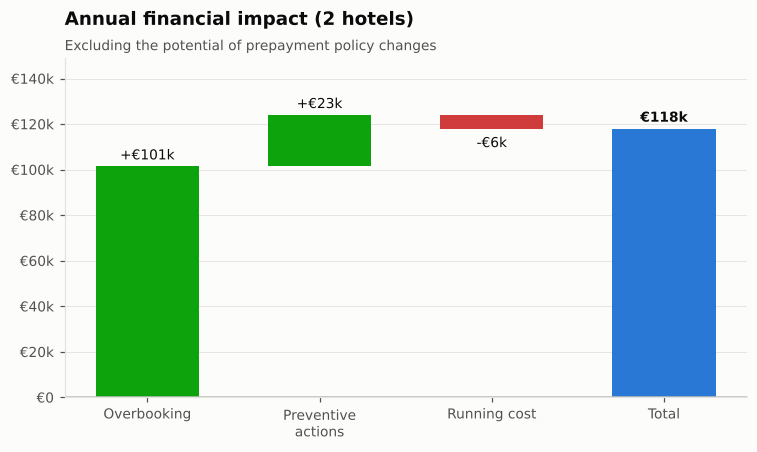

,EUR / year,Source
Item,,
"Model-based overbooking (backtest, annualised)","€101,436",public data + synthetic turned-away demand
Preventive actions for high-risk bookings,"€22,563",SYNTHETIC experiment
Cost of running the solution,"-€6,000",assumption
TOTAL (excluding policy changes),"€118,000",
Additionally: potential of prepayment policy changes (to be validated by a test),"€131,684","what-if simulation, SYNTHETIC assumptions"
For comparison: overbooking upper bound (oracle),"€274,538",backtest


In [2]:
show(T["kpi"])
show(F["business"])
show(T["business_items"])

## 2. Diagnosis: scale of the cancellation problem
How many bookings never turn into a stay, when cancellations happen and how often the hotels are full.

,City hotel,Resort hotel
Bookings,"78,898","39,666"
Cancellation rate,40.8%,27.3%
No-show rate,1.2%,0.7%
Share of cancellations made in the last 7 days,12.0%,11.6%
Avg. booking lead time (days),110,93
Avg. rate per night (ADR) [EUR],€107,€92
Revenue cancelled late (<=7 days) [EUR],"€1,167,163","€366,324"
Revenue lost to no-shows [EUR],"€361,170","€88,311"


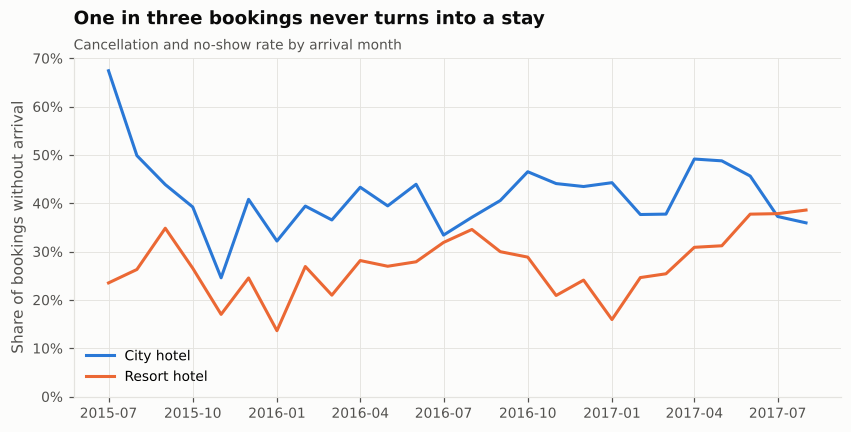

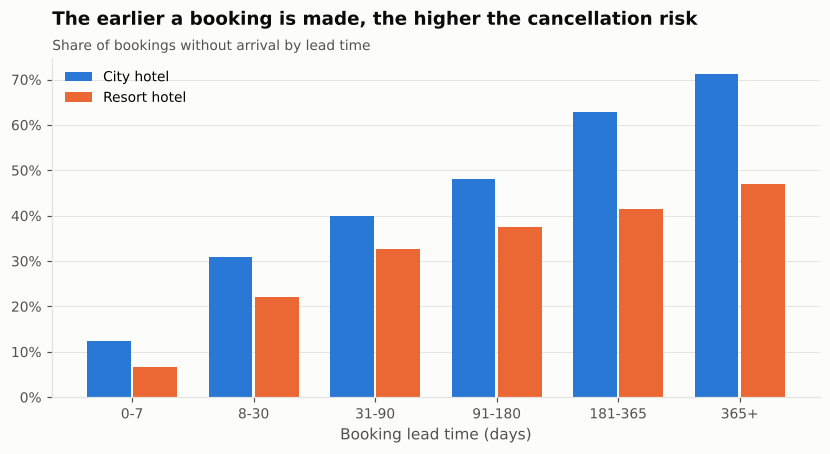

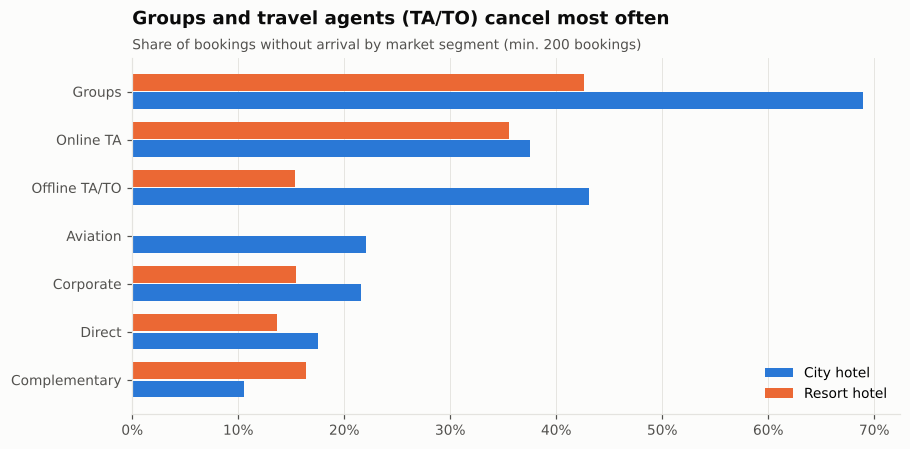

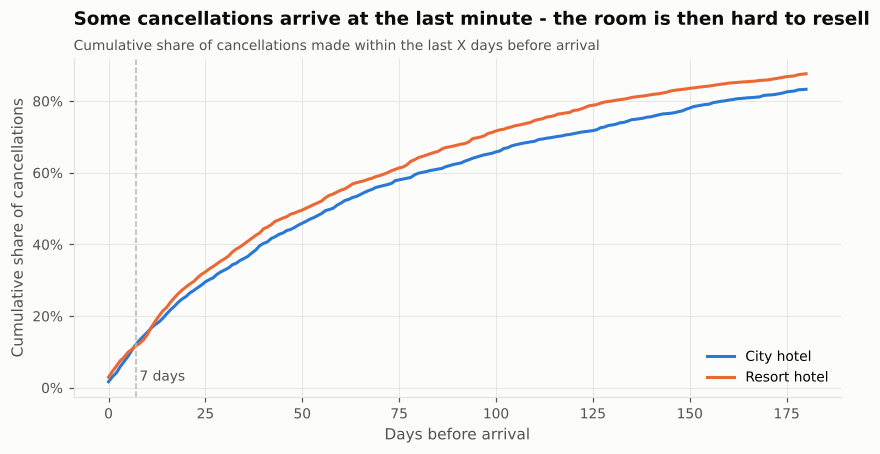

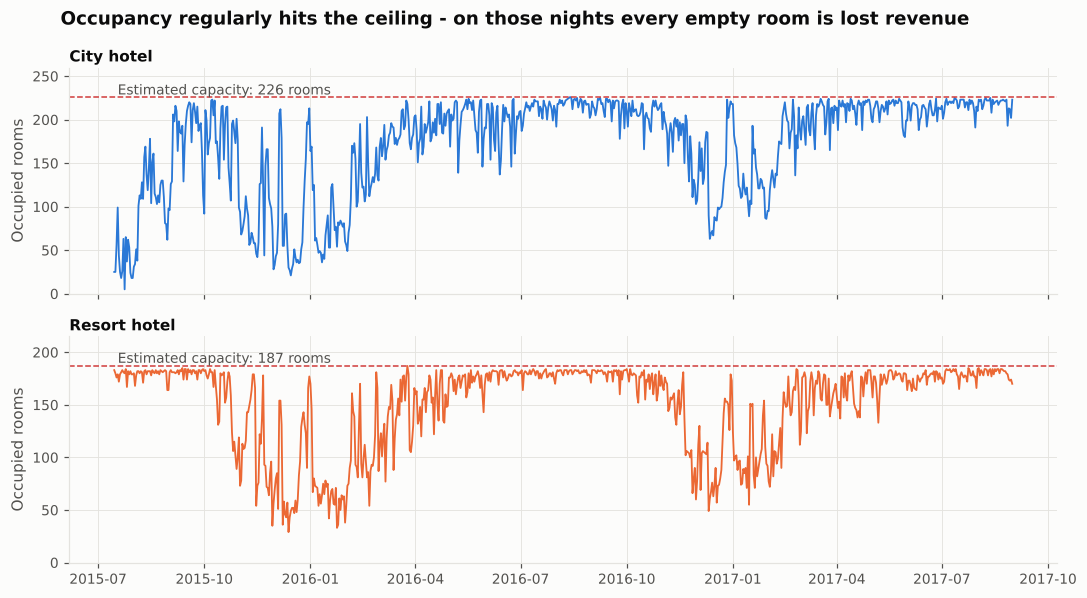

In [3]:
show(T["eda_summary"], decimals={"Bookings": 0, "Avg. booking lead time (days)": 0}, transpose=True)
show(F["eda_trend"])
show(F["eda_lead"])
show(F["eda_segment"])
show(F["eda_timing"])
show(F["eda_occupancy"])

## 3. No-arrival risk model
The model scores risk on a specific day before arrival (D-0 ... D-180) using only information
available on that day (**leakage-free snapshots**). Time-based validation:
training 07.2015-06.2016, calibration 07-12.2016, test 01-08.2017.

,ROC_AUC,PR_AUC,Brier,LogLoss,ECE,Mean predicted,Mean actual
Segment heuristic (current practice),0.783,0.378,0.0785,0.2770,2.2%,12.8%,10.7%
Logistic regression,0.759,0.420,0.0785,0.2841,1.1%,11.7%,10.7%
LightGBM (uncalibrated),0.802,0.449,0.0752,0.2646,0.2%,10.7%,10.7%
LightGBM + calibration (target model),0.802,0.438,0.0754,0.2655,0.8%,11.4%,10.7%


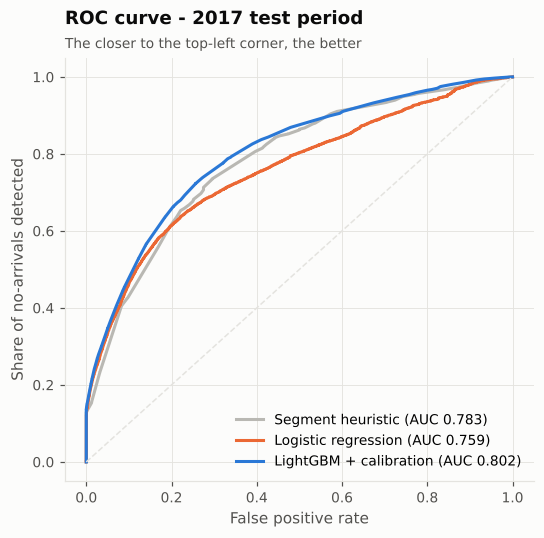

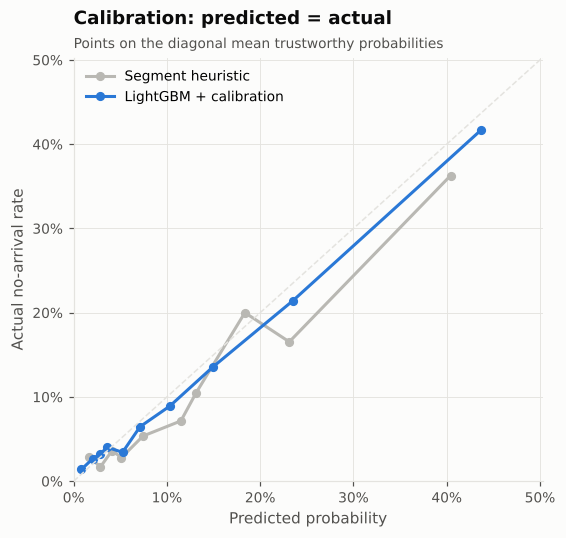

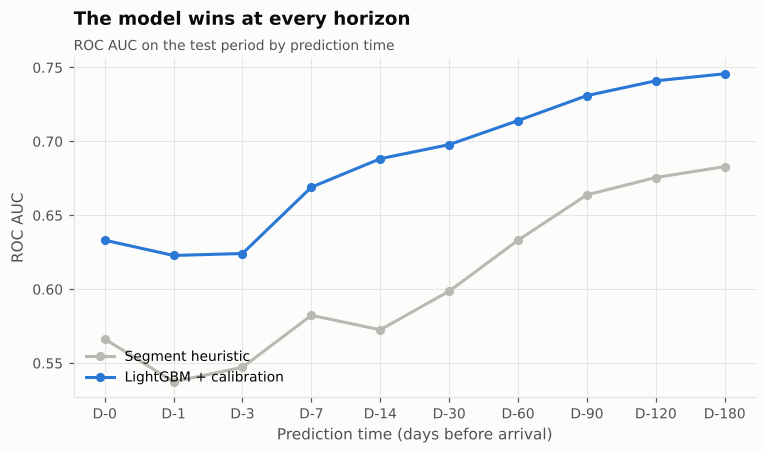

,Bookings,No-arrival rate,ROC AUC (heuristic),ROC AUC (LightGBM),Brier (heuristic),Brier (LightGBM)
Days to arrival (D-h),,,,,,
0,"25,391",2.4%,0.566,0.633,0.0235,0.0227
1,"23,836",2.8%,0.537,0.623,0.0274,0.0264
3,"22,447",3.4%,0.547,0.624,0.0326,0.0321
7,"21,110",5.3%,0.582,0.669,0.0523,0.0500
14,"20,002",9.3%,0.573,0.688,0.0810,0.0788
30,"17,816",14.1%,0.599,0.698,0.1151,0.1086
60,"15,187",19.4%,0.633,0.714,0.1364,0.1322
90,"12,908",23.7%,0.664,0.731,0.1543,0.1455
120,"10,724",27.9%,0.676,0.741,0.1663,0.1606


In [4]:
show(T["model_comparison"], decimals={"ROC_AUC": 3, "PR_AUC": 3, "Brier": 4, "LogLoss": 4})
show(F["model_roc"])
show(F["model_calibration"])
show(F["model_auc_horizon"])
show(T["model_by_horizon"], decimals={"ROC AUC (heuristic)": 3, "ROC AUC (LightGBM)": 3,
                                      "Brier (heuristic)": 4, "Brier (LightGBM)": 4})

## 4. Why guests do not arrive (SHAP)
SHAP values computed natively by LightGBM. Note: the high risk for the *Non Refund* deposit
is a known artefact of this dataset (such bookings are almost always cancelled).

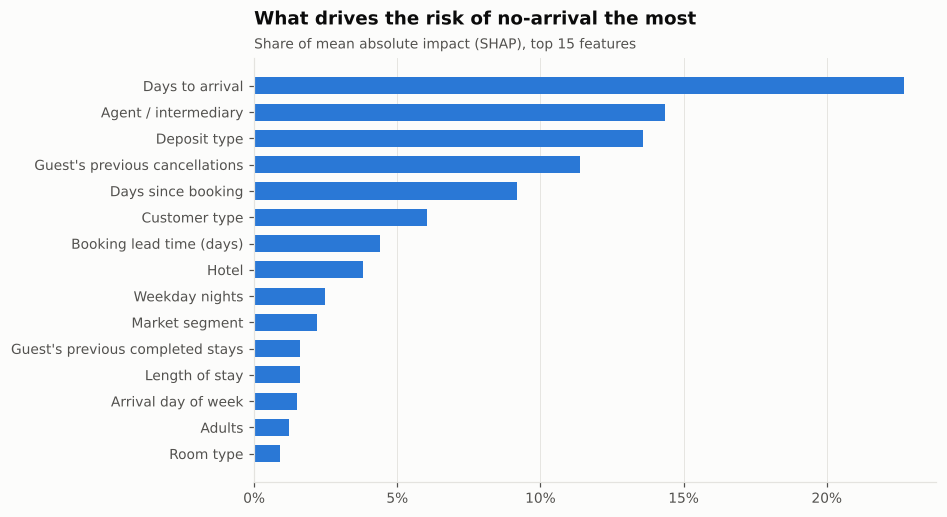

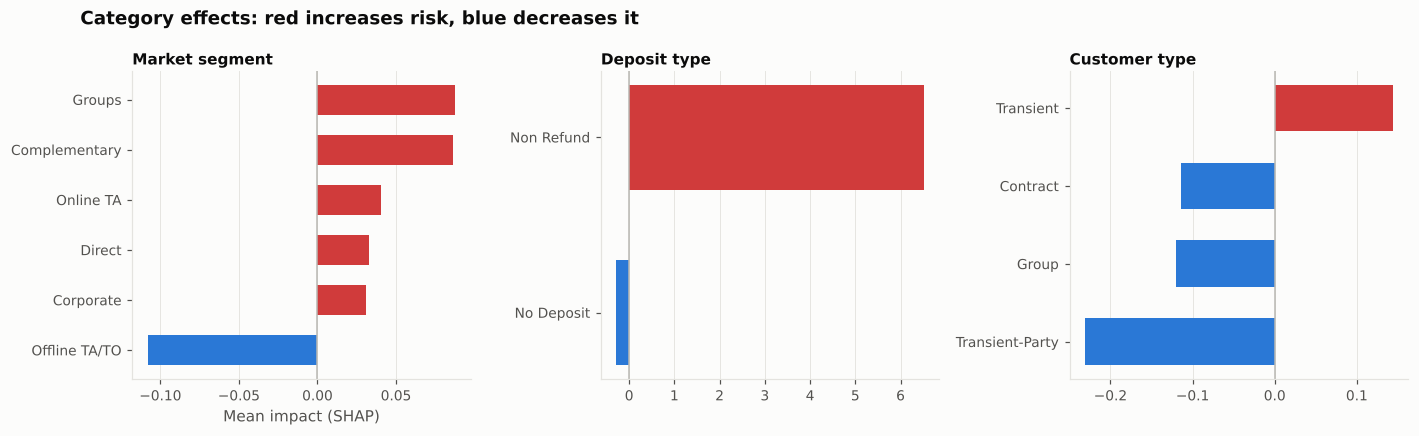

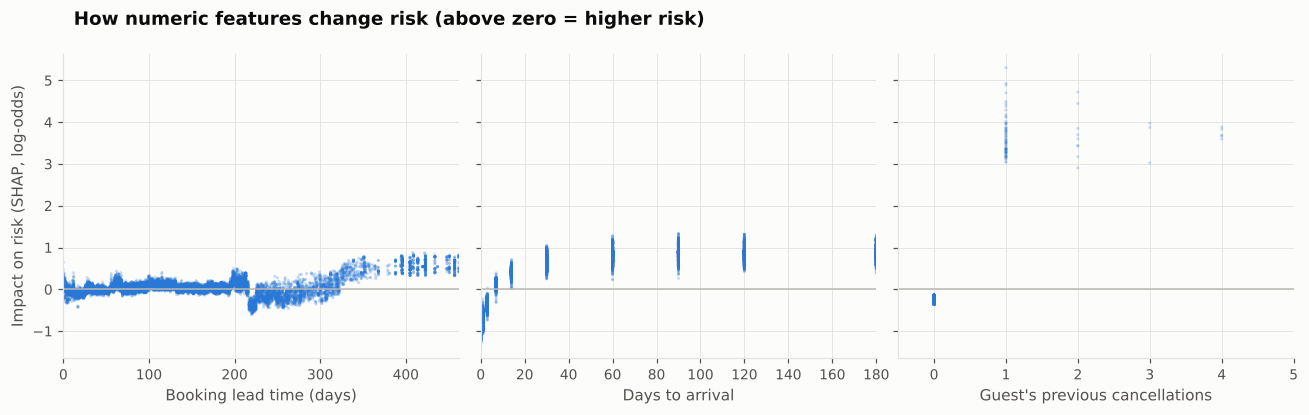

In [5]:
show(F["shap_importance"])
show(F["shap_categories"])
show(F["shap_dependence"])

## 5. Occupancy forecast
The structural forecast (bookings x probability of arrival + expected new bookings)
is corrected by a stage-2 model; uncertainty intervals come from cross-validation residuals.

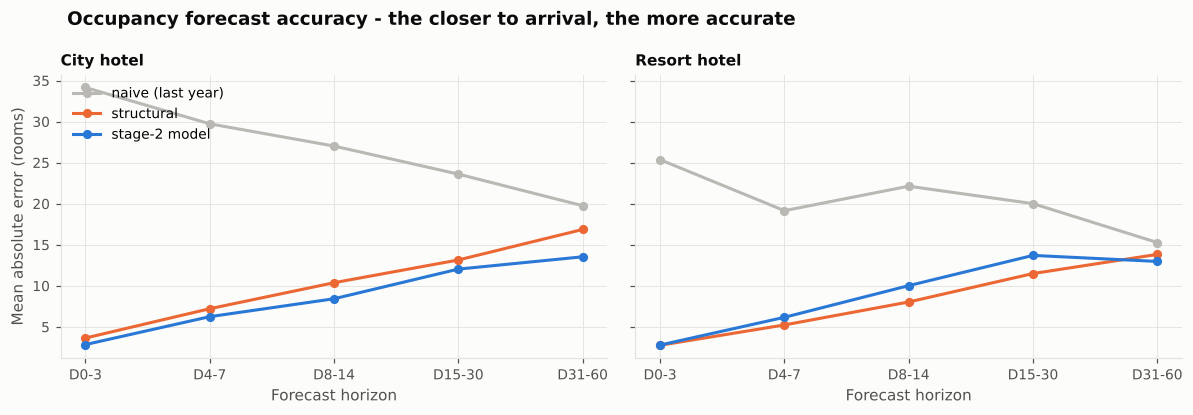

MAE: naive (last year) MAE: structural MAE: stage-2 model Nights
Hotel        Horizon                                                                 
City Hotel   D0-3                     34.15            3.64               2.85     52
             D4-7                     29.73            7.21               6.24     52
             D8-14                    27.02           10.38               8.42     91
             D15-30                   23.61           13.15              12.04    208
             D31-60                   19.76           16.86              13.53    377
Resort Hotel D0-3                     25.37            2.76               2.79     52
             D4-7                     19.15            5.23               6.16     52
             D8-14                    22.13            8.03              10.02     91
             D15-30                   20.01           11.49              13.70    208
             D31-60                   15.28           13.83              12.97    377

In [6]:
show(F["forecast_accuracy"])
show(T["forecast_accuracy"], decimals={"Nights": 0})

## 6. Overbooking - 2017 backtest
For each night the decision was taken at D-3, based solely on what was known at the time.
Comparison: current practice, static 5% overbooking, ML model, oracle (upper bound).

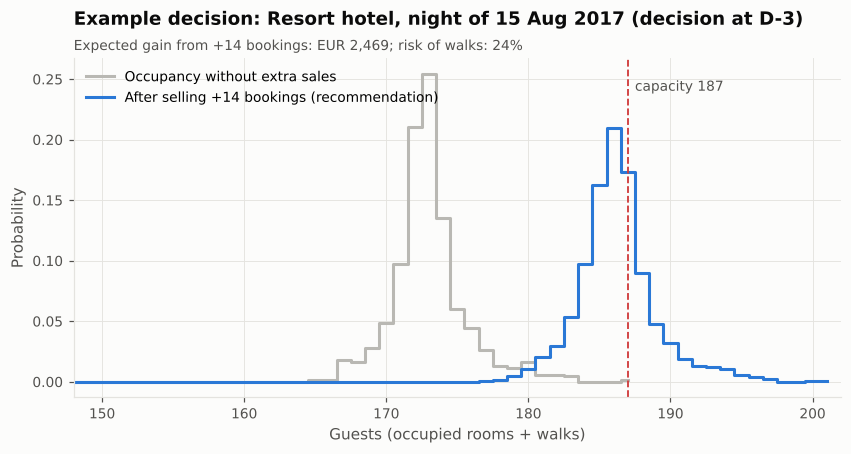

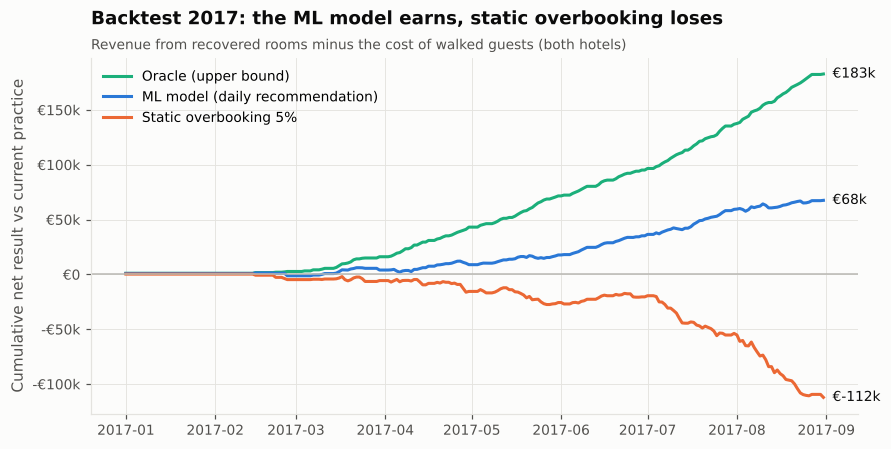

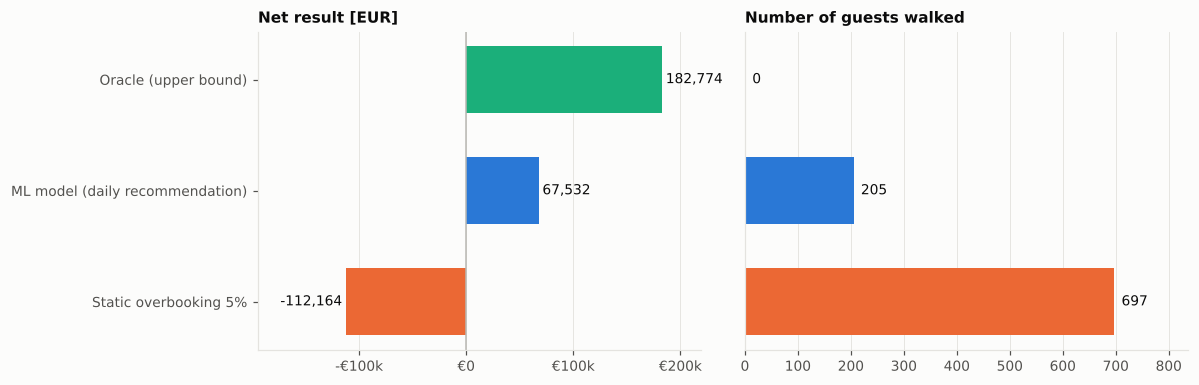

,Recovered room-nights,Guests walked,Nights with walks,Revenue from recovered rooms [EUR],Walk cost [EUR],Net result [EUR],% of potential
Policy,,,,,,,
No extra sales (current practice),0,0,0,€0,€0,€0,0.0%
Static overbooking 5%,"1,156",697,160,"€179,031","€291,195","-€112,164",-61.4%
ML model (daily recommendation),977,205,73,"€149,741","€82,209","€67,532",36.9%
Oracle (upper bound),"1,181",0,0,"€182,774",€0,"€182,774",100.0%


In [7]:
show(F["ob_example"])
show(F["ob_cumulative"])
show(F["ob_bars"])
show(T["backtest_summary"])

## 7. Overbooking plan for the next 60 days (production mode)

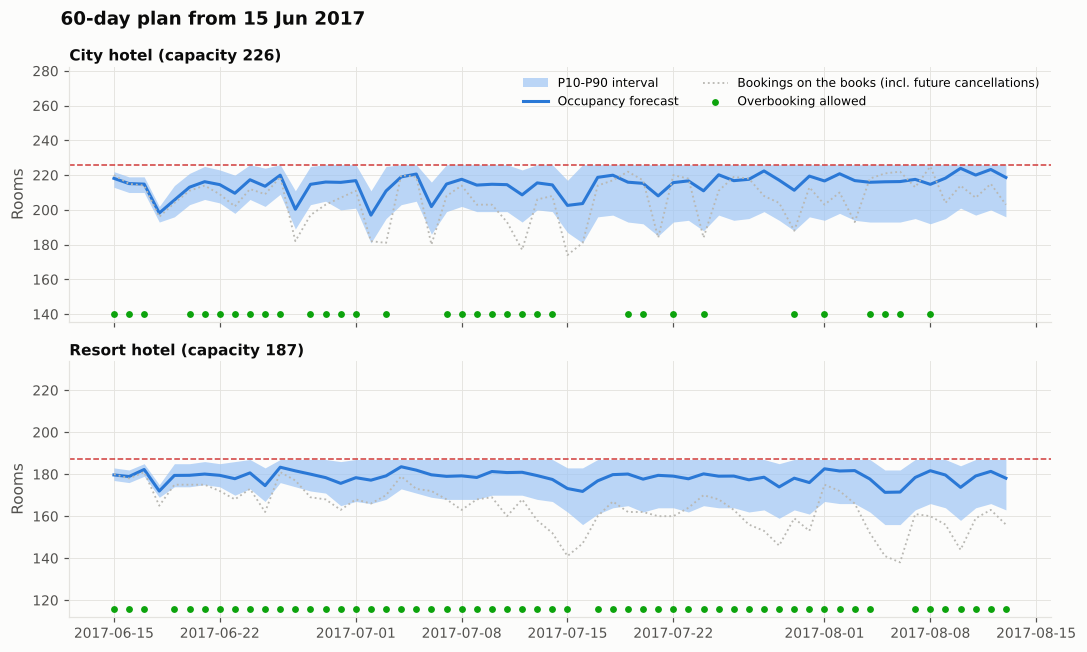

,hotel,night,horizon,capacity,in_house,on_books,forecast,occ_p10,occ_p90,p_full,x_opt,exp_gain,recommendation
0,City Hotel,2017-06-15,0,226,142,78,218.15,213,222,0.03,7,571.18,Allow overbooking: +7 bookings
1,City Hotel,2017-06-16,1,226,85,130,215.14,210,219,0.01,10,954.71,Allow overbooking: +10 bookings
2,City Hotel,2017-06-17,2,226,37,177,214.83,210,219,0.01,10,"1,028.94",Allow overbooking: +10 bookings
3,City Hotel,2017-06-18,3,226,17,179,198.18,193,202,0.00,29,"3,326.75",Low occupancy - sales push / promotion
4,City Hotel,2017-06-19,4,226,5,199,205.67,196,214,0.00,18,"1,747.76",Low occupancy - sales push / promotion
5,City Hotel,2017-06-20,5,226,1,210,213.06,203,221,0.04,10,751.38,Allow overbooking: +10 bookings
6,City Hotel,2017-06-21,6,226,1,213,216.23,206,225,0.08,6,376.79,Allow overbooking: +6 bookings
7,City Hotel,2017-06-22,7,226,1,208,214.54,204,223,0.06,8,553.92,Allow overbooking: +8 bookings
8,City Hotel,2017-06-23,8,226,1,201,209.58,198,220,0.03,13,888.97,Allow overbooking: +13 bookings
9,City Hotel,2017-06-24,9,226,1,211,217.35,206,226,0.18,4,98.58,Allow overbooking: +4 bookings


In [8]:
show(F["forward_plan"])
plan = T["forward_plan"][["hotel", "night", "horizon", "capacity", "in_house", "on_books", "forecast",
                          "occ_p10", "occ_p90", "p_full", "x_opt", "exp_gain", "recommendation"]]
show(plan, max_rows=20)

## 8. High-risk bookings (arrival within 14 days)

In [9]:
show(T["risk_summary"])
show(T["risk_list"], max_rows=25, decimals={"Booking ID (pseudonym)": 0, "Days to arrival": 0, "Nights": 0})

,Value
Active bookings (arrival within 14 days),"1,424"
Phone contact,0
E-mail contact,227
Expected no-arrivals,95.22
Actual no-arrivals (verification),61
Revenue at risk [EUR],"€40,377"


,Booking ID (pseudonym),Hotel,Arrival,Days to arrival,Nights,Channel,Segment,Deposit,ADR [EUR],Booking value [EUR],No-arrival risk,Revenue at risk [EUR],Recommended action,Main risk drivers,Did not arrive (verification)
0,"71,085",City hotel,2017-06-28,13,1,Corporate,Corporate,No Deposit,€100,€100,30.1%,€30,E-mail: ask the guest to confirm arrival + pre...,Days to arrival: 13; Distribution channel: Cor...,1
1,"70,574",City hotel,2017-06-18,3,8,TA/TO,Online TA,No Deposit,€162,"€1,292",30.1%,€389,E-mail: ask the guest to confirm arrival + pre...,Agent / intermediary: A8; Length of stay: 8; H...,1
2,"114,851",City hotel,2017-06-27,12,1,TA/TO,Online TA,No Deposit,€99,€99,30.1%,€30,E-mail: ask the guest to confirm arrival + pre...,Agent / intermediary: A9; Days to arrival: 12;...,0
3,"71,019",City hotel,2017-06-27,12,3,TA/TO,Online TA,No Deposit,€126,€379,28.2%,€107,E-mail: ask the guest to confirm arrival + pre...,Agent / intermediary: A9; Days to arrival: 12;...,1
4,"114,880",City hotel,2017-06-27,12,1,TA/TO,Online TA,No Deposit,€99,€99,28.2%,€28,E-mail: ask the guest to confirm arrival + pre...,Days to arrival: 12; Agent / intermediary: A9;...,0
5,"114,906",City hotel,2017-06-27,12,1,TA/TO,Online TA,No Deposit,€119,€119,28.2%,€34,E-mail: ask the guest to confirm arrival + pre...,Agent / intermediary: A9; Days to arrival: 12;...,0
6,"114,979",City hotel,2017-06-29,14,1,Direct,Direct,No Deposit,€185,€185,28.2%,€52,E-mail: ask the guest to confirm arrival + pre...,Agent / intermediary: A14; Days to arrival: 14...,0
7,"114,672",City hotel,2017-06-23,8,2,TA/TO,Online TA,No Deposit,€160,€320,28.2%,€90,E-mail: ask the guest to confirm arrival + pre...,Days since booking: 0; Agent / intermediary: A...,0
8,"114,901",City hotel,2017-06-27,12,1,TA/TO,Online TA,No Deposit,€99,€99,28.2%,€28,E-mail: ask the guest to confirm arrival + pre...,Days to arrival: 12; Agent / intermediary: A9;...,0
9,"115,146",City hotel,2017-06-28,13,4,TA/TO,Online TA,No Deposit,€180,€720,28.2%,€203,E-mail: ask the guest to confirm arrival + pre...,Agent / intermediary: A9; Days to arrival: 13;...,0


## 9. Preventive actions - A/B test of guest contact  *(SYNTHETIC)*
The effect of contact was applied synthetically to real bookings to demonstrate the evaluation method:
difference in rates with a confidence interval, effect by risk decile and choosing the group worth contacting.

,Value
Bookings in experiment,"20,002"
No-arrival rate - control,9.5%
No-arrival rate - contacted,7.6%
Reduction (pp),1.9%
95% CI lower,1.2%
95% CI upper,2.7%
Recommended risk threshold for contact,12.0%
Deciles to contact,"7, 8, 9, 10"
Share of bookings to contact,41.3%


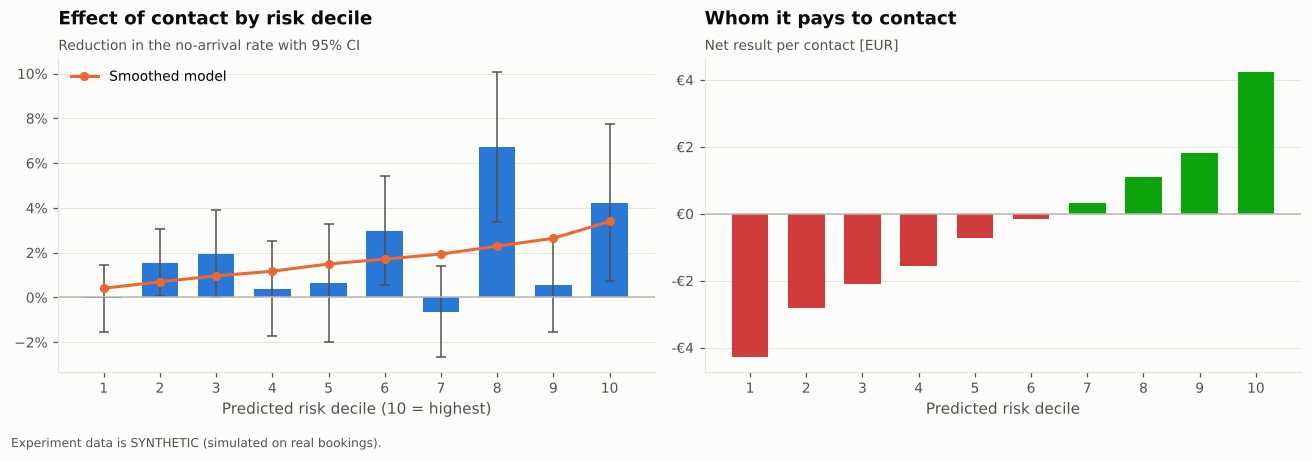

,Mean predicted risk,Bookings,No-arrivals - control,No-arrivals - contacted,Uplift (pp),CI lower,CI upper,Uplift - smoothed model,Avg. booking revenue [EUR],Value saved / contact [EUR],Cost / contact [EUR],Net result / contact [EUR]
Risk decile,,,,,,,,,,,,
1,1.6%,"2,001",2.9%,3.0%,-0.0%,-1.5%,1.4%,0.4%,€605,€1,€5,-€4
2,3.2%,"2,000",3.7%,2.2%,1.6%,0.1%,3.0%,0.7%,€483,€2,€5,-€3
3,4.9%,"2,000",6.2%,4.2%,2.0%,0.0%,3.9%,1.0%,€480,€2,€4,-€2
4,6.4%,"2,000",6.4%,6.1%,0.4%,-1.7%,2.5%,1.2%,€474,€3,€4,-€2
5,8.9%,"2,000",10.3%,9.6%,0.7%,-2.0%,3.3%,1.5%,€429,€3,€4,-€1
6,10.7%,"2,000",9.8%,6.8%,3.0%,0.6%,5.4%,1.7%,€451,€4,€4,-€0
7,12.7%,"2,000",5.4%,6.1%,-0.6%,-2.7%,1.4%,1.9%,€425,€4,€4,€0
8,16.1%,"2,000",21.3%,14.6%,6.7%,3.4%,10.1%,2.3%,€406,€5,€4,€1
9,19.5%,"2,000",6.3%,5.7%,0.5%,-1.5%,2.6%,2.6%,€393,€5,€3,€2


In [10]:
show(T["outreach_overall"])
show(F["outreach_uplift"])
show(T["outreach_deciles"])

## 10. Cancellation and prepayment policies

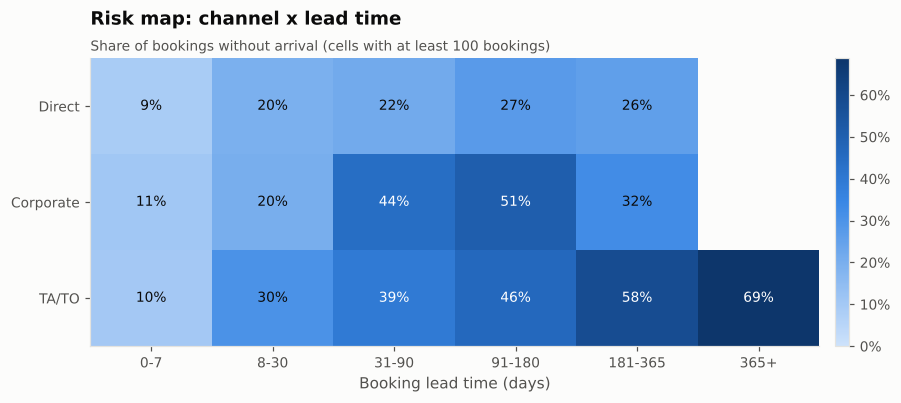

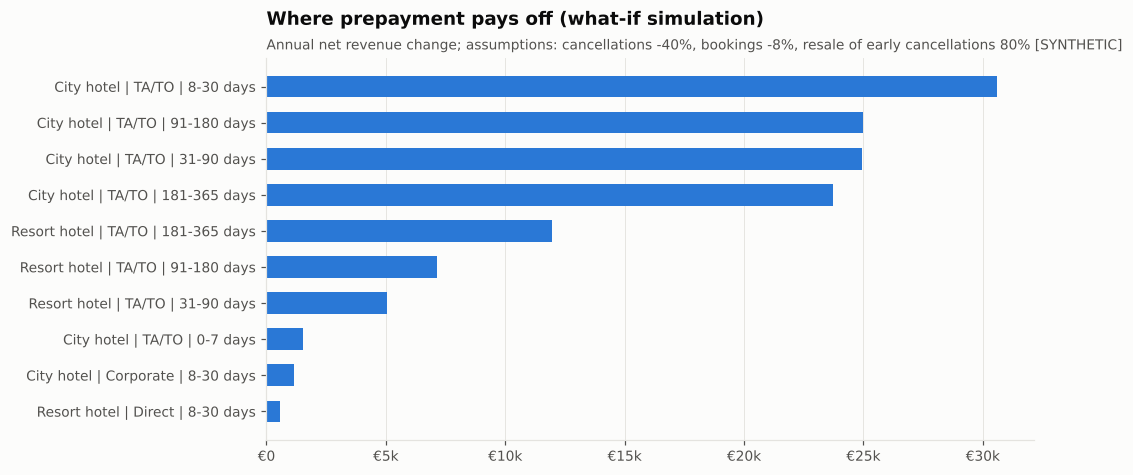

,Hotel,Channel,Lead time (days),Bookings,Cancellation rate,Late cancellation rate,Revenue change per year [EUR],Recommendation
33,City hotel,TA/TO,8-30,"9,873",28.9%,9.1%,"€30,602",Introduce prepayment / shorter free-cancellati...
34,City hotel,TA/TO,91-180,"13,545",35.7%,3.3%,"€24,997",Introduce prepayment / shorter free-cancellati...
31,City hotel,TA/TO,31-90,"16,835",32.8%,4.1%,"€24,956",Introduce prepayment / shorter free-cancellati...
30,City hotel,TA/TO,181-365,"8,802",43.8%,2.4%,"€23,707",Introduce prepayment / shorter free-cancellati...
75,Resort hotel,TA/TO,181-365,"5,515",38.6%,1.2%,"€11,961",Introduce prepayment / shorter free-cancellati...
79,Resort hotel,TA/TO,91-180,"6,362",34.6%,1.5%,"€7,157",Introduce prepayment / shorter free-cancellati...
76,Resort hotel,TA/TO,31-90,"6,566",32.7%,2.1%,"€5,057",Introduce prepayment / shorter free-cancellati...
29,City hotel,TA/TO,0-7,"6,194",10.3%,10.3%,"€1,541",Introduce prepayment / shorter free-cancellati...
3,City hotel,Corporate,8-30,823,17.7%,12.0%,"€1,133",Introduce prepayment / shorter free-cancellati...
63,Resort hotel,Direct,8-30,"1,202",17.6%,7.7%,€572,Introduce prepayment / shorter free-cancellati...


,Hotel,Channel,Bookings,Cancellation rate,No-show rate,Revenue cancelled per year [EUR]
0,City hotel,Corporate,"3,365",21.5%,1.6%,"€53,194"
1,City hotel,Direct,"6,678",16.0%,2.4%,"€197,058"
2,City hotel,GDS,190,17.9%,1.6%,"€4,586"
3,City hotel,TA/TO,"68,661",44.2%,1.0%,"€4,592,419"
5,Resort hotel,Corporate,"3,219",20.1%,1.2%,"€71,631"
6,Resort hotel,Direct,"7,773",16.2%,0.9%,"€287,871"
7,Resort hotel,TA/TO,"28,673",31.1%,0.6%,"€2,292,216"


In [11]:
show(F["policy_heat"])
show(F["policy_whatif"])
show(T["policy_whatif"][["Hotel", "Channel", "Lead time (days)", "Bookings", "Cancellation rate",
                         "Late cancellation rate", "Revenue change per year [EUR]", "Recommendation"]], max_rows=12)
show(T["channels"])

## 11. Model monitoring (data drift and stability)

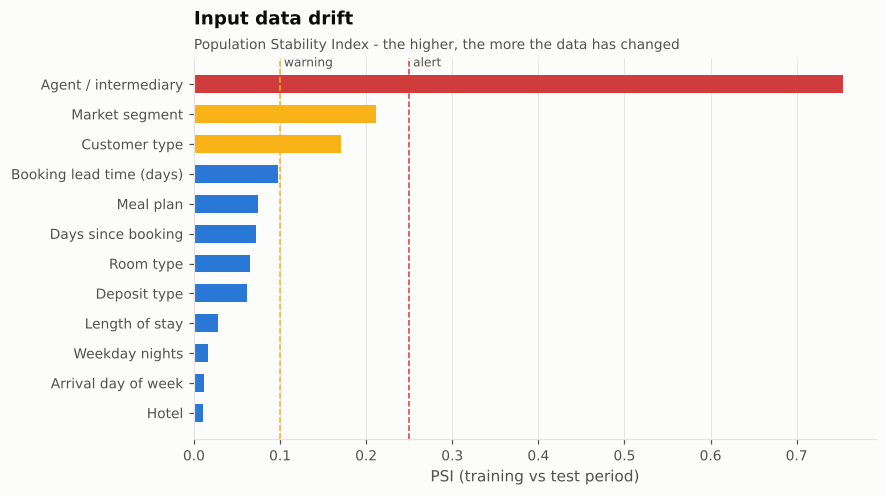

,Feature,PSI,Status
0,Agent / intermediary,0.754,ALERT
1,Market segment,0.211,Warning
2,Customer type,0.170,Warning
3,Booking lead time (days),0.097,OK
4,Meal plan,0.075,OK
5,Days since booking,0.072,OK
6,Room type,0.065,OK
7,Deposit type,0.062,OK
8,Length of stay,0.027,OK
9,Weekday nights,0.016,OK


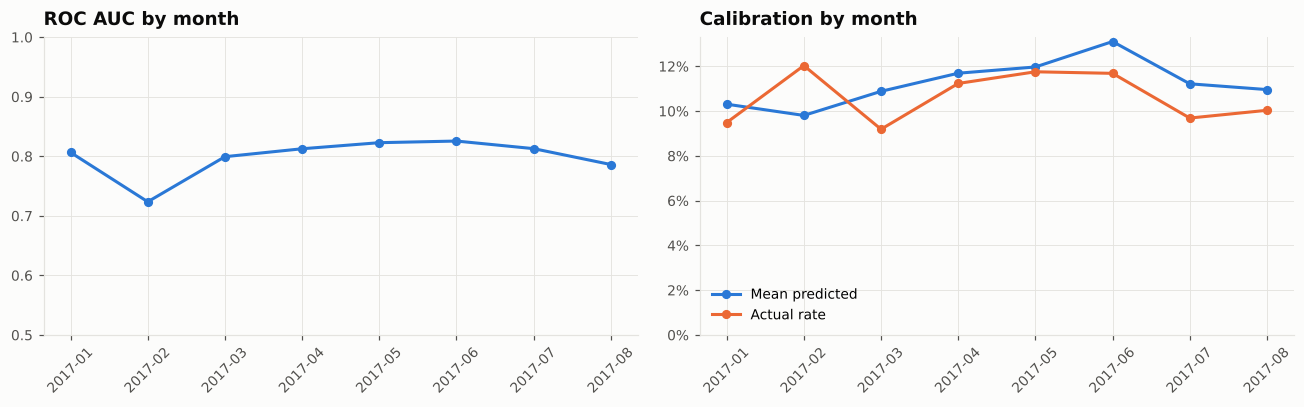

,Snapshots,ROC AUC,Brier,Mean predicted,Actual rate,Calibration error,Status
Arrival month,,,,,,,
2017-01,"11,384",0.806,0.0704,10.3%,9.5%,0.8%,OK
2017-02,"15,135",0.724,0.0927,9.8%,12.0%,-2.2%,OK
2017-03,"20,917",0.799,0.0674,10.9%,9.2%,1.7%,OK
2017-04,"23,740",0.813,0.0788,11.7%,11.2%,0.5%,OK
2017-05,"26,668",0.823,0.0770,12.0%,11.8%,0.2%,OK
2017-06,"25,433",0.826,0.0718,13.1%,11.7%,1.4%,OK
2017-07,"27,394",0.813,0.0724,11.2%,9.7%,1.5%,OK
2017-08,"25,092",0.786,0.0762,11.0%,10.0%,0.9%,OK


In [12]:
show(F["drift"])
show(T["drift"], decimals={"PSI": 3}, max_rows=15)
show(F["monthly"])
show(T["monthly"], decimals={"ROC AUC": 3, "Brier": 4})

## 12. Assumptions and limitations

In [13]:
show(T["assumptions"])

,Value,Source
Assumption,,
Hotel capacity,max. realised occupancy,Estimated from data (the dataset has no room c...
Cost of walking a guest,2.0 x ADR + EUR 150,SYNTHETIC
Ancillary spend per room-night,"{'Resort Hotel': 35.0, 'City Hotel': 20.0}",SYNTHETIC
Sold-out night (turned-away demand exists),>= 95% of capacity,SYNTHETIC
Turned-away demand on a sold-out night,Poisson(10% of capacity),SYNTHETIC
Overbooking decision time,D-3,Parameter
Benchmark policy,static overbooking 5%,Parameter
Max. effect of guest contact,30% fewer cancellations,SYNTHETIC
Cost per contact,EUR 1,SYNTHETIC


## 13. Export: HTML report and Excel
The HTML report (a single file with charts) can be sent to the client; the Excel file contains the full tables.

In [ ]:
html_path = write_html(R)
xlsx_path = write_excel(R)
print(html_path)
print(xlsx_path)
# import webbrowser; webbrowser.open(html_path.resolve().as_uri())   # open in the browser